# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.


## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en el archivo **`student_work/Proyecto2/heap.py`**. La celda de abajo guarda directamente el contenido en esa ruta; ejecútela cada vez que modifique la clase.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él.
- La celda de prueba agrega la carpeta de entrega a la ruta de importación y recarga `heap.py` para usar los cambios.
- No olvide hacer *commit* y *push* de `student_work/Proyecto2/heap.py` a su repositorio.

In [6]:
%%writefile heap.py
class Heap:
    def __init__(self):
        self.arreglo = [float('-inf')]

    def insert(self, valor, imagen=False):
        self.arreglo.append(valor)
        self._subir(len(self.arreglo) - 1)
        if imagen:
            self._mostrar()

    def remove_smallest(self, imagen=False):
        if len(self.arreglo) == 1:
            raise IndexError('No se puede retirar de un heap vacío.')

        smallest = self.arreglo[1]
        last = self.arreglo.pop()
        if len(self.arreglo) > 1:
            self.arreglo[1] = last
            self._bajar(1)
        if imagen:
            self._mostrar()
        return smallest

    def build_heap(self, lista, imagen=False):
        self.arreglo = [float('-inf')] + list(lista)
        last_parent = (len(self.arreglo) - 1) // 2
        for index in range(last_parent, 0, -1):
            self._bajar(index)
        if imagen:
            self._mostrar()

    def _subir(self, index):
        while index > 1:
            parent = index // 2
            if self.arreglo[parent] <= self.arreglo[index]:
                break
            self.arreglo[parent], self.arreglo[index] = (
                self.arreglo[index], self.arreglo[parent]
            )
            index = parent

    def _bajar(self, index):
        size = len(self.arreglo) - 1
        while 2 * index <= size:
            child = 2 * index
            right = child + 1
            if right <= size and self.arreglo[right] < self.arreglo[child]:
                child = right
            if self.arreglo[index] <= self.arreglo[child]:
                break
            self.arreglo[index], self.arreglo[child] = (
                self.arreglo[child], self.arreglo[index]
            )
            index = child

    def _mostrar(self):
        import matplotlib.pyplot as plt

        size = len(self.arreglo) - 1
        depth = size.bit_length() - 1 if size else 0
        figure, axis = plt.subplots(
            figsize=(max(5, 1.5 * (2 ** min(depth, 4))), max(3, 1.25 * depth + 2))
        )

        for index in range(1, size + 1):
            level = index.bit_length() - 1
            position = index - (1 << level)
            x = (position + 0.5) * 2 / (1 << level) - 1
            y = depth - level

            if index > 1:
                parent = index // 2
                parent_level = parent.bit_length() - 1
                parent_position = parent - (1 << parent_level)
                parent_x = (parent_position + 0.5) * 2 / (1 << parent_level) - 1
                parent_y = depth - parent_level
                axis.plot([parent_x, x], [parent_y, y], color='#64748b', zorder=1)

            axis.scatter([x], [y], s=1100, color='#d7eee8', edgecolor='#176b5b', zorder=2)
            axis.text(x, y, str(self.arreglo[index]), ha='center', va='center', zorder=3)

        axis.set_xlim(-1.15, 1.15)
        axis.set_ylim(-0.6, depth + 0.6)
        axis.axis('off')
        figure.tight_layout()
        plt.show()


Writing heap.py


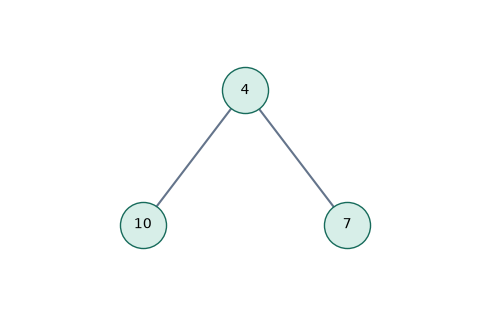

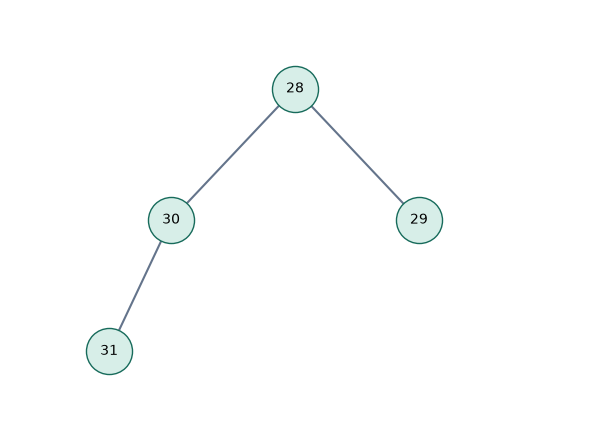

In [7]:
import importlib
import sys
from pathlib import Path

module_dir = (Path.cwd() / '../student_work/Proyecto2').resolve()
sys.path.insert(0, str(module_dir))

import heap
importlib.reload(heap)
from heap import Heap

H = Heap()

H.insert(10)
H.insert(4)
H.insert(7, imagen=True)

assert H.arreglo == [float('-inf'), 4, 10, 7]

assert H.remove_smallest() == 4

H.build_heap([31, 30, 29, 28], imagen=True)

assert H.arreglo[1] == 28
       